<a href="https://colab.research.google.com/github/mlk272150-creator/german-credit-risk-analysis/blob/main/German_Credit_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import pandas as pd

df = pd.read_csv('/content/german_credit_data - german_credit_data.csv')

df.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


استخدمت مكتبة Pandas لأنها بتساعدني أقرأ البيانات وأتعامل معها على شكل جدول. استخدمت `read_csv` لقراءة ملف البيانات اللي رفعته على Colab، وخزّنت البيانات في متغير اسمه `df` حتى أقدر أرجع أستخدمها في الخطوات التالية. أما `head()` فبتعرض أول خمسة صفوف من الجدول، حتى أتأكد إن البيانات انقرأت بشكل صحيح وأشوف شكلها قبل ما أبدأ بتحليلها.

In [35]:
import os

os.listdir('/content')

['.config', 'german_credit_data - german_credit_data.csv', 'sample_data']

هذا الكود بخليني أشوف أسماء الملفات الموجودة داخل مساحة العمل في Google Colab

In [36]:
df.shape

(1000, 10)

استخدمت `shape` عشان أعرف حجم جدول البيانات اللي قرأته، يعني كم صف وكم عمود موجودين فيه

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Age              1000 non-null   int64 
 1   Sex              1000 non-null   object
 2   Job              1000 non-null   int64 
 3   Housing          1000 non-null   object
 4   SavingAccounts   817 non-null    object
 5   CheckingAccount  606 non-null    object
 6   CreditAmount     1000 non-null   int64 
 7   Duration         1000 non-null   int64 
 8   Purpose          1000 non-null   object
 9   Risk             1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB


استخدمت `info()` حتى أفحص بنية جدول البيانات، وأعرف نوع البيانات في كل عمود، وعدد القيم غير المفقودة

In [38]:
df.isnull().sum()

,0
Age,0
Sex,0
Job,0
Housing,0
SavingAccounts,183
CheckingAccount,394
CreditAmount,0
Duration,0
Purpose,0
Risk,0


استخدمت هذا الكود حتى أعرف عدد القيم المفقودة في كل عمود. فهمت إن `isnull()` بفحص إذا كانت القيمة مفقودة، وبعطيني نتيجة منطقية لكل خلية، أما `sum()` فبتجمع القيم المفقودة في كل عمود

In [39]:
print("SavingAccounts:")
print(df['SavingAccounts'].value_counts())

print("\nCheckingAccount:")
print(df['CheckingAccount'].value_counts())

print("\nRisk:")
print(df['Risk'].value_counts())

SavingAccounts:
SavingAccounts
little        603
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64

CheckingAccount:
CheckingAccount
little      274
moderate    269
rich         63
Name: count, dtype: int64

Risk:
Risk
good    700
bad     300
Name: count, dtype: int64


استخدمت `value_counts()` حتى أعرف عدد مرات ظهور كل فئة داخل الأعمدة. بدي أفهم أنواع حسابات التوفير والحسابات الجارية الموجودة بالبيانات، وأعرف كمان عدد السجلات المصنفة `good` و`bad`. هالمعلومات بتساعدني أفهم توزيع البيانات قبل ما أقرر كيف أتعامل مع القيم المفقودة أو أختار التحليلات المناسبة.

In [40]:
df['Duration'].describe()

,Duration
count,1000.000000
mean,20.903000
std,12.058814
min,4.000000
25%,12.000000
50%,18.000000
75%,24.000000
max,72.000000


استخدمت `describe()` على عمود مدة القرض حتى أعرف ملخصًا إحصائيًا عنه، مثل أقل مدة وأعلى مدة ومتوسط مدة القروض. هالمعلومات بتساعدني أفهم كيف تتوزع مدد القروض قبل ما أقارنها مع تصنيف المخاطر `Risk`.

In [41]:
df['DurationGroup'] = pd.cut(
    df['Duration'],
    bins=[0, 12, 24, float('inf')],
    labels=['Short (<=12 months)',
            'Medium (13-24 months)',
            'Long (>24 months)']
)

df['DurationGroup'].value_counts().sort_index()

,count
DurationGroup,
Short (<=12 months),359
Medium (13-24 months),411
Long (>24 months),230


استخدمت `pd.cut()` حتى أقسم مدد القروض إلى ثلاث فئات بدل ما أتعامل مع كل مدة كرقم منفصل. اخترت الفئات القصيرة والمتوسطة والطويلة بناءً على ملخص مدد القروض، بحيث أقدر أقارن تصنيف المخاطر بين مجموعات واضحة. وبعدها استخدمت `value_counts()` لمعرفة عدد القروض الموجودة في كل فئة، حتى أفهم توزيع البيانات قبل ما أقارنها مع `Risk`.

In [42]:
pd.crosstab(df['DurationGroup'], df['Risk'])

Risk,bad,good
DurationGroup,,
Short (<=12 months),76,283
Medium (13-24 months),122,289
Long (>24 months),102,128


هذا الكود ينشئ جدولًا يبيّن عدد القروض الجيدة والسيئة في كل فئة من فئات المدة.

In [43]:
pd.crosstab(
    df['DurationGroup'],
    df['Risk'],
    normalize='index'
) * 100

Risk,bad,good
DurationGroup,,
Short (<=12 months),21.169916,78.830084
Medium (13-24 months),29.683698,70.316302
Long (>24 months),44.347826,55.652174


بعد ما قارنت أعداد القروض، انتبهت إن كل فئة فيها عدد مختلف من القروض، لذلك استخدمت النسب المئوية حتى أقارن نسبة القروض المصنّفة bad داخل كل فئة بشكل عادل، بدل الاعتماد على الأعداد فقط.

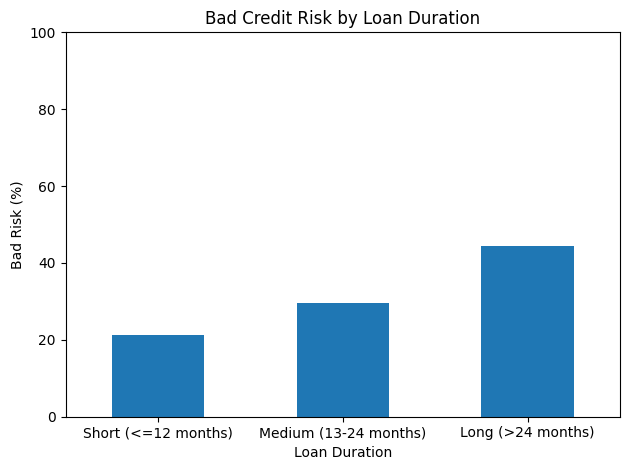

In [44]:
import matplotlib.pyplot as plt

risk_percent = pd.crosstab(
    df['DurationGroup'],
    df['Risk'],
    normalize='index'
) * 100

risk_percent['bad'].plot(
    kind='bar',
    ylabel='Bad Risk (%)',
    xlabel='Loan Duration',
    title='Bad Credit Risk by Loan Duration',
    ylim=(0, 100)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [45]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# الخصائص التي سيستخدمها النموذج
X = df.drop(columns=['Risk', 'DurationGroup'], errors='ignore')

# التصنيف الذي نريد التنبؤ به
y = df['Risk']

# تحديد الأعمدة الرقمية والفئوية
numeric_cols = ['Age', 'CreditAmount', 'Duration']

categorical_cols = [
    'Sex', 'Job', 'Housing',
    'SavingAccounts', 'CheckingAccount', 'Purpose'
]

# تجهيز الأعمدة الرقمية
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# تجهيز الأعمدة الفئوية
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# جمع خطوات التجهيز
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

# تقسيم البيانات إلى تدريب واختبار
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# نموذج الانحدار اللوجستي
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

# نموذج مرجعي يتوقع الفئة الأكثر شيوعًا دائمًا
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)
model.fit(X_train, y_train)

# تقييم النموذجين على بيانات الاختبار
baseline_pred = baseline.predict(X_test)
model_pred = model.predict(X_test)

for name, predictions in [
    ('Baseline', baseline_pred),
    ('Logistic Regression', model_pred)
]:
    print(f'\n{name}')
    print('Accuracy:', round(
        accuracy_score(y_test, predictions), 3
    ))
    print('Precision for bad:', round(
        precision_score(
            y_test, predictions,
            pos_label='bad', zero_division=0
        ), 3
    ))
    print('Recall for bad:', round(
        recall_score(
            y_test, predictions,
            pos_label='bad', zero_division=0
        ), 3
    ))
    print('F1 for bad:', round(
        f1_score(
            y_test, predictions,
            pos_label='bad', zero_division=0
        ), 3
    ))

print('\nConfusion matrix for Logistic Regression')
print(confusion_matrix(
    y_test, model_pred,
    labels=['bad', 'good']
))


Baseline
Accuracy: 0.7
Precision for bad: 0.0
Recall for bad: 0.0
F1 for bad: 0.0

Logistic Regression
Accuracy: 0.745
Precision for bad: 0.6
Recall for bad: 0.45
F1 for bad: 0.514

Confusion matrix for Logistic Regression
[[ 27  33]
 [ 18 122]]


بدي أنتقل إلى بناء نموذج يتعلم من خصائص القروض السابقة حتى يتوقع تصنيف مخاطر قرض جديد. رح أفصل بيانات التدريب عن بيانات الاختبار، حتى أقيّم النموذج على بيانات ما استخدمها أثناء التعلم، وأقارن أداءه بتوقع بسيط

In [46]:

# استبعاد السجلات التي لا تحتوي على فئة مدخرات
savings_data = df.dropna(subset=["SavingAccounts"]).copy()

# حساب عدد القروض ونسبة bad داخل كل فئة
savings_risk = (
    savings_data.groupby("SavingAccounts")["Risk"]
    .agg(
        Total_Loans="count",
        Bad_Loans=lambda x: (x == "bad").sum()
    )
    .reset_index()
)

savings_risk["Bad_Rate_%"] = (
    savings_risk["Bad_Loans"]
    / savings_risk["Total_Loans"] * 100
).round(2)

# ترتيب النتائج من أعلى نسبة bad إلى أقل نسبة
savings_risk = savings_risk.sort_values(
    "Bad_Rate_%", ascending=False
)

display(savings_risk)


,SavingAccounts,Total_Loans,Bad_Loans,Bad_Rate_%
0,little,603,217,35.99
1,moderate,103,34,33.01
2,quite rich,63,11,17.46
3,rich,48,6,12.50


ريد معرفة ما إذا كانت نسبة القروض المصنّفة bad تختلف بين فئات المدخرات.

In [47]:

import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

# استبعاد السجلات التي لا تحتوي على فئة مدخرات
test_data = df.dropna(subset=["SavingAccounts"]).copy()

# جدول تكراري يربط فئة المدخرات بتصنيف القرض
contingency_table = pd.crosstab(
    test_data["SavingAccounts"],
    test_data["Risk"]
)

print("Observed counts:")
display(contingency_table)

# اختبار Chi-square
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# حساب Cramér's V لقياس قوة العلاقة
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6f}")
print(f"Cramér's V: {cramers_v:.3f}")

# التحقق من الأعداد المتوقعة اللازمة لتقييم صلاحية الاختبار
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected counts:")
display(expected_table.round(2))

print(
    "\nNumber of expected counts below 5:",
    int((expected < 5).sum()),
    "out of",
    expected.size
)


Observed counts:


Risk,bad,good
SavingAccounts,,
little,217,386
moderate,34,69
quite rich,11,52
rich,6,42


Chi-square statistic: 18.479
Degrees of freedom: 3
p-value: 0.000350
Cramér's V: 0.150

Expected counts:


Risk,bad,good
SavingAccounts,,
little,197.80,405.20
moderate,33.79,69.21
quite rich,20.67,42.33
rich,15.75,32.25



Number of expected counts below 5: 0 out of 8


عد ملاحظة انخفاض نسبة القروض المصنّفة bad مع ارتفاع فئة المدخرات، سنستخدم اختبار Chi-square  لفحص وجود علاقة إحصائية بين SavingAccounts وRisk. وسنحسب أيضًا Cramér’s V لتقدير قوة العلاقة، لأن الدلالة الإحصائية وحدها لا توضح مدى أهمية العلاقة عمليًا

In [48]:
print("Housing:")
print(df["Housing"].value_counts(dropna=False))

print("\nSavingAccounts:")
print(df["SavingAccounts"].value_counts(dropna=False))

Housing:
Housing
own     713
rent    179
free    108
Name: count, dtype: int64

SavingAccounts:
SavingAccounts
little        603
NaN           183
moderate      103
quite rich     63
rich           48
Name: count, dtype: int64


  الكود هاد لنعرف إذا الأشخاص اللي بيمتلكوا منازل عندهم مستويات مدخرات مختلفة عن الأشخاص اللي بستأجروا أو ساكنين مجانًا.

In [49]:
import pandas as pd
from IPython.display import display

# استبعاد الأشخاص الذين لا نعرف فئة مدخراتهم
df_savings = df.dropna(subset=["SavingAccounts"]).copy()

# 1. جدول الأعداد
counts = pd.crosstab(
    df_savings["Housing"],
    df_savings["SavingAccounts"]
)

counts.index.name = "Housing (نوع السكن)"
counts.columns.name = "SavingAccounts (فئة المدخرات)"

print("جدول 1: عدد الأشخاص حسب نوع السكن وفئة المدخرات")
display(counts.style.set_caption("عدد الأشخاص"))

# 2. جدول النسب المئوية داخل كل نوع سكن
percentages = pd.crosstab(
    df_savings["Housing"],
    df_savings["SavingAccounts"],
    normalize="index"
) * 100

percentages.index.name = "Housing (نوع السكن)"
percentages.columns.name = "SavingAccounts (فئة المدخرات)"

print("جدول 2: النسب المئوية داخل كل نوع سكن")
display(
    percentages.style
    .format("{:.2f}%")
    .set_caption("النسب المئوية")
)

جدول 1: عدد الأشخاص حسب نوع السكن وفئة المدخرات


SavingAccounts (فئة المدخرات),little,moderate,quite rich,rich
Housing (نوع السكن),,,,
free,67,10,6,2
own,430,71,45,37
rent,106,22,12,9


جدول 2: النسب المئوية داخل كل نوع سكن


SavingAccounts (فئة المدخرات),little,moderate,quite rich,rich
Housing (نوع السكن),,,,
free,78.82%,11.76%,7.06%,2.35%
own,73.76%,12.18%,7.72%,6.35%
rent,71.14%,14.77%,8.05%,6.04%


يوضح عدد الأشخاص في كل فئة مدخرات داخل كل نوع سكن، ثم حسبنا النسب المئوية داخل كل نوع سكن. لأن عدد أصحاب المنازل أكبر بكثير من باقي الفئات.

In [50]:
import pandas as pd
from scipy.stats import chi2_contingency
from IPython.display import display

# جدول الأعداد الذي حسبناه سابقًا
counts = pd.crosstab(
    df_savings["Housing"],
    df_savings["SavingAccounts"]
)

# إجراء اختبار كاي تربيع
chi2, p_value, dof, expected = chi2_contingency(counts)

# عرض النتائج في جدول مرتب
results = pd.DataFrame({
    "المقياس": [
        "Chi-square statistic",
        "Degrees of freedom",
        "P-value",
        "عدد السجلات المستخدمة"
    ],
    "القيمة": [
        round(chi2, 4),
        dof,
        round(p_value, 6),
        int(counts.to_numpy().sum())
    ]
})

display(results)

print(
    "التفسير:",
    "توجد أدلة إحصائية على وجود علاقة بين نوع السكن والمدخرات."
    if p_value < 0.05
    else "لم نجد أدلة إحصائية كافية على وجود علاقة بين نوع السكن والمدخرات."
)

,المقياس,القيمة
0,Chi-square statistic,3.208600
1,Degrees of freedom,6.000000
2,P-value,0.782248
3,عدد السجلات المستخدمة,817.000000


التفسير: لم نجد أدلة إحصائية كافية على وجود علاقة بين نوع السكن والمدخرات.


نتيجة اختبار  P-value = 0.782248، وهي أكبر من 0.05. لذلك ما عندنا دليل إحصائي كافٍ على وجود علاقة بين نوع السكن وفئة المدخرات في هذه البيانات.

,القيمة
count,1000.00
mean,35.55
std,11.38
min,19.00
25%,27.00
50%,33.00
75%,42.00
max,75.00


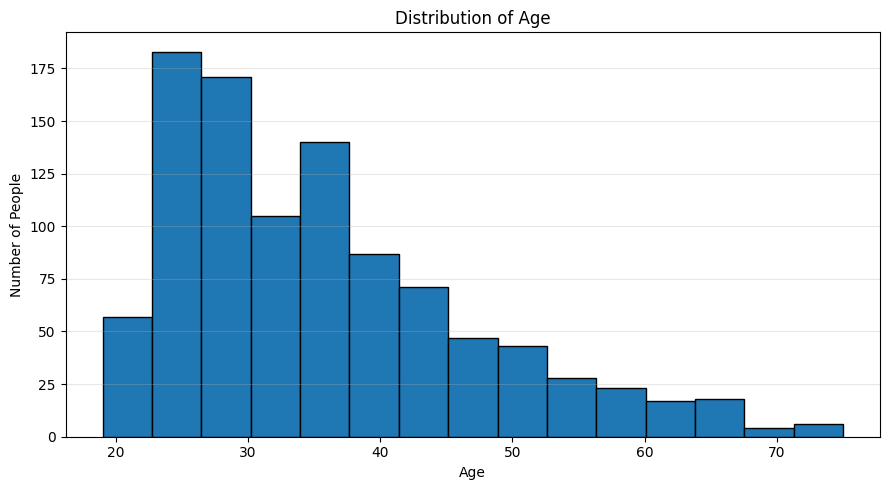

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. ملخص الأعمار
age_summary = df["Age"].describe().to_frame(name="القيمة")
display(age_summary.style.format("{:.2f}"))

# 2.  توزيع الأعمار
plt.figure(figsize=(9, 5))
plt.hist(df["Age"].dropna(), bins=15, edgecolor="black")
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of People")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

عدد الأشخاص حسب الفئة العمرية والمدخرات


SavingAccounts,little,moderate,quite rich,rich
AgeGroup,,,,
25 or younger,123,22,11,6
26-35,245,54,21,20
36-45,128,14,18,10
46-55,64,9,8,7
Over 55,43,4,5,5


النسب المئوية داخل كل فئة عمرية


SavingAccounts,little,moderate,quite rich,rich
AgeGroup,,,,
25 or younger,75.93%,13.58%,6.79%,3.70%
26-35,72.06%,15.88%,6.18%,5.88%
36-45,75.29%,8.24%,10.59%,5.88%
46-55,72.73%,10.23%,9.09%,7.95%
Over 55,75.44%,7.02%,8.77%,8.77%


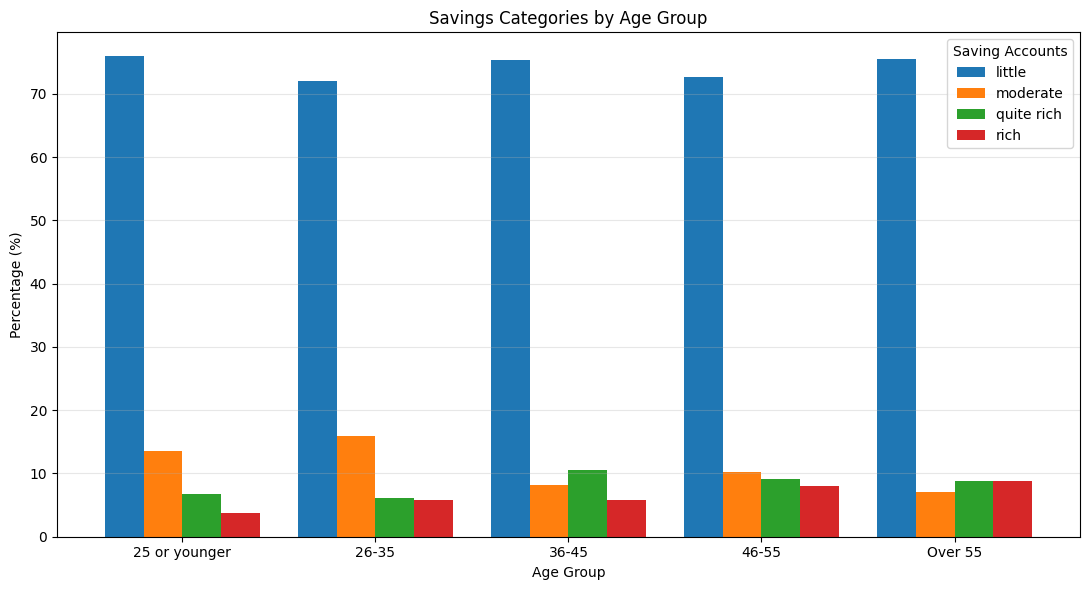

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


df_age_savings = df.dropna(
    subset=["Age", "SavingAccounts"]
).copy()


df_age_savings["AgeGroup"] = pd.cut(
    df_age_savings["Age"],
    bins=[0, 25, 35, 45, 55, float("inf")],
    labels=[
        "25 or younger",
        "26-35",
        "36-45",
        "46-55",
        "Over 55"
    ]
)


counts = pd.crosstab(
    df_age_savings["AgeGroup"],
    df_age_savings["SavingAccounts"]
)

print("عدد الأشخاص حسب الفئة العمرية والمدخرات")
display(counts)


percentages = pd.crosstab(
    df_age_savings["AgeGroup"],
    df_age_savings["SavingAccounts"],
    normalize="index"
) * 100

print("النسب المئوية داخل كل فئة عمرية")
display(percentages.style.format("{:.2f}%"))


percentages.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Savings Categories by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Saving Accounts")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd
from scipy.stats import chi2_contingency
from IPython.display import display

# جدول العلاقة بين الفئة العمرية والمدخرات
counts = pd.crosstab(
    df_age_savings["AgeGroup"],
    df_age_savings["SavingAccounts"]
)

# الاختبار الإحصائي
chi2, p_value, dof, expected = chi2_contingency(counts)

# عرض النتائج
results = pd.DataFrame({
    "المقياس": [
        "Chi-square statistic",
        "Degrees of freedom",
        "P-value",
        "عدد السجلات"
    ],
    "القيمة": [
        round(chi2, 4),
        dof,
        round(p_value, 6),
        int(counts.to_numpy().sum())
    ]
})

display(results)

if p_value < 0.05:
    print("النتيجة: توجد أدلة إحصائية على وجود علاقة بين الفئة العمرية وفئة المدخرات.")
else:
    print("النتيجة: لا توجد أدلة إحصائية كافية على وجود علاقة بين الفئة العمرية وفئة المدخرات.")

,المقياس,القيمة
0,Chi-square statistic,13.828600
1,Degrees of freedom,12.000000
2,P-value,0.311789
3,عدد السجلات,817.000000


النتيجة: لا توجد أدلة إحصائية كافية على وجود علاقة بين الفئة العمرية وفئة المدخرات.


قيمة P-value = 0.311789، وهي أكبر من 0.05؛ لذلك لا توجد أدلة إحصائية كافية على وجود علاقة بين الفئة العمرية وفئة المدخرات في هذه العينة

عدد القروض ونسبة القروض عالية المخاطر حسب الغرض


Risk,bad,good,Total,Bad Rate (%)
Purpose,,,,
vacation/others,5,7,12,41.67%
education,23,36,59,38.98%
repairs,8,14,22,36.36%
business,34,63,97,35.05%
domestic appliances,4,8,12,33.33%
furniture/equipment,58,123,181,32.04%
car,106,231,337,31.45%
radio/TV,62,218,280,22.14%


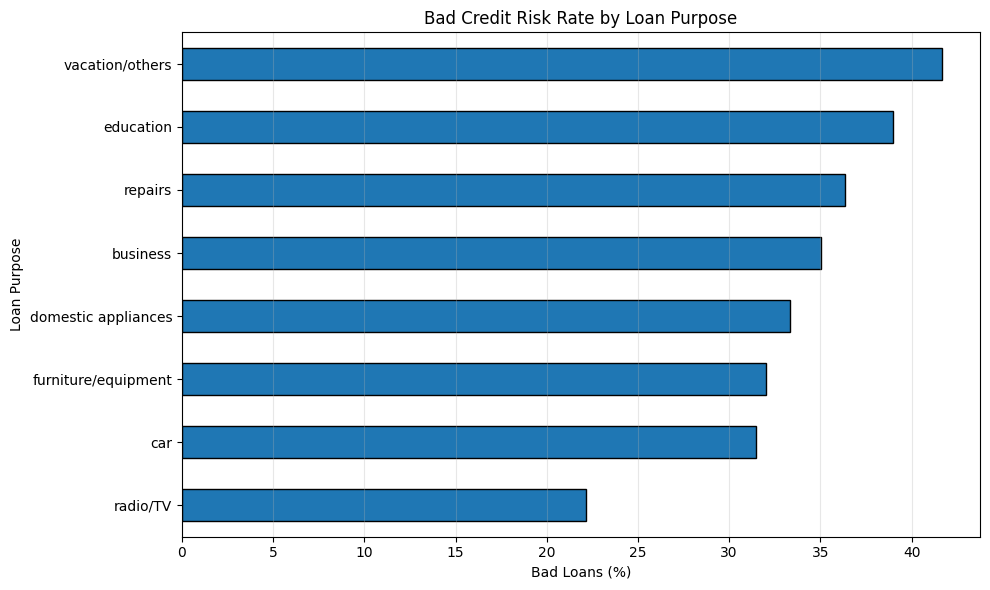

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# استبعاد السجلات التي لا تحتوي على الغرض أو تصنيف المخاطر
df_purpose = df.dropna(subset=["Purpose", "Risk"]).copy()

# 1. جدول عدد القروض حسب الغرض وتصنيف المخاطر
counts = pd.crosstab(
    df_purpose["Purpose"],
    df_purpose["Risk"]
)

# 2. حساب نسبة القروض عالية المخاطر داخل كل غرض
bad_rate = (
    df_purpose.assign(IsBad=df_purpose["Risk"].eq("bad"))
    .groupby("Purpose", observed=True)["IsBad"]
    .mean()
    .mul(100)
)

# دمج النتائج في جدول واحد
results = counts.copy()
results["Total"] = results.sum(axis=1)
results["Bad Rate (%)"] = bad_rate.round(2)
results = results.sort_values("Bad Rate (%)", ascending=False)

print("عدد القروض ونسبة القروض عالية المخاطر حسب الغرض")
display(results.style.format({"Bad Rate (%)": "{:.2f}%"}))

# 3. رسم بياني لنسبة القروض عالية المخاطر
plt.figure(figsize=(10, 6))

bad_rate.sort_values().plot(kind="barh", edgecolor="black")

plt.title("Bad Credit Risk Rate by Loan Purpose")
plt.xlabel("Bad Loans (%)")
plt.ylabel("Loan Purpose")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
from scipy.stats import chi2_contingency
import pandas as pd
from IPython.display import display

counts = pd.crosstab(df["Purpose"], df["Risk"])

chi2, p_value, dof, expected = chi2_contingency(counts)

results = pd.DataFrame({
    "المقياس": [
        "Chi-square statistic",
        "Degrees of freedom",
        "P-value",
        "عدد السجلات"
    ],
    "القيمة": [
        round(chi2, 4),
        dof,
        round(p_value, 6),
        int(counts.to_numpy().sum())
    ]
})

display(results)

,المقياس,القيمة
0,Chi-square statistic,13.642100
1,Degrees of freedom,7.000000
2,P-value,0.057926
3,عدد السجلات,1000.000000


قيمة P-value = 0.057926 أكبر قليلًا من مستوى الدلالة الذي اخترناه، وهو 0.05.
لذلك، لا توجد أدلة إحصائية كافية عند مستوى 5% لإثبات وجود علاقة بين الغرض من القرض وتصنيف المخاطر.